# Teen Mental Health Dataset — Exploratory Data Analysis (EDA)


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DATASET_PATH = Path("data/raw/Teen_Mental_Health_Dataset.csv")
if not DATASET_PATH.exists():
    DATASET_PATH = Path("../data/raw/Teen_Mental_Health_Dataset.csv")
df = pd.read_csv(DATASET_PATH)
df.head()

,age,gender,daily_social_media_hours,platform_usage,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,social_interaction_level,stress_level,anxiety_level,depression_risk
0,19,male,3.8,Instagram,6.5,1.7,2.77,1.2,low,6,6,medium
1,16,male,6.5,Other,5.8,0.6,2.57,0.2,medium,9,7,high
2,17,female,2.9,Other,7.0,1.2,3.04,1.7,high,3,2,low
3,19,female,7.9,TikTok,5.0,1.6,2.21,1.2,medium,10,8,medium
4,15,female,1.2,TikTok,8.8,0.9,3.61,1.9,high,1,2,low


# 1. Dataset overview

In [16]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("Data type"))
print("\nFirst five rows:")
display(df.head())

Rows and columns: (2500, 12)

Column names:
['age', 'gender', 'daily_social_media_hours', 'platform_usage', 'sleep_hours', 'screen_time_before_sleep', 'academic_performance', 'physical_activity', 'social_interaction_level', 'stress_level', 'anxiety_level', 'depression_risk']

Data types:


,Data type
age,int64
gender,object
daily_social_media_hours,float64
platform_usage,object
sleep_hours,float64
screen_time_before_sleep,float64
academic_performance,float64
physical_activity,float64
social_interaction_level,object
stress_level,int64



First five rows:


,age,gender,daily_social_media_hours,platform_usage,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,social_interaction_level,stress_level,anxiety_level,depression_risk
0,19,male,3.8,Instagram,6.5,1.7,2.77,1.2,low,6,6,medium
1,16,male,6.5,Other,5.8,0.6,2.57,0.2,medium,9,7,high
2,17,female,2.9,Other,7.0,1.2,3.04,1.7,high,3,2,low
3,19,female,7.9,TikTok,5.0,1.6,2.21,1.2,medium,10,8,medium
4,15,female,1.2,TikTok,8.8,0.9,3.61,1.9,high,1,2,low


# 2. Data quality checks

In [17]:

quality_summary = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique(),
    "data_type": df.dtypes.astype(str)
})
display(quality_summary)
print("Duplicate rows:", df.duplicated().sum())

,missing_values,unique_values,data_type
age,0,7,int64
gender,0,2,object
daily_social_media_hours,0,71,float64
platform_usage,0,4,object
sleep_hours,0,51,float64
screen_time_before_sleep,0,26,float64
academic_performance,0,200,float64
physical_activity,0,21,float64
social_interaction_level,0,3,object
stress_level,0,10,int64


Duplicate rows: 0


# 3. Target variable: depression_risk

,count,percentage
depression_risk,,
low,1266,50.64
medium,650,26.00
high,584,23.36


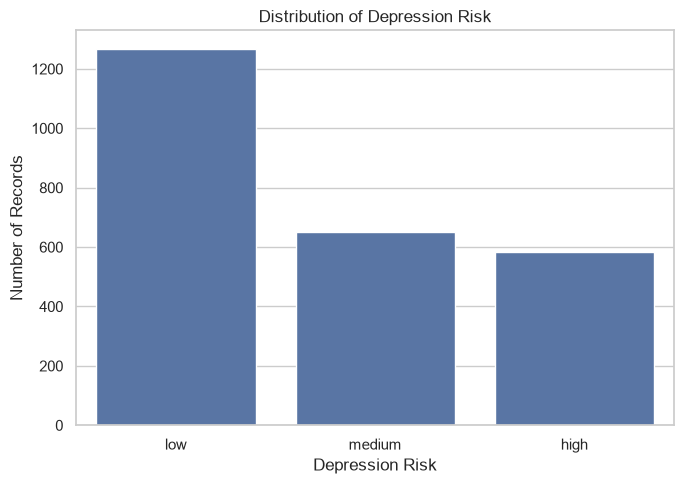

In [18]:
risk_order = ["low", "medium", "high"]
risk_counts = df["depression_risk"].value_counts().reindex(risk_order, fill_value=0)
risk_percentages = (df["depression_risk"].value_counts(normalize=True) * 100).reindex(risk_order, fill_value=0)

display(pd.DataFrame({
    "count": risk_counts,
    "percentage": risk_percentages.round(2)
}))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="depression_risk", order=risk_order)
plt.title("Distribution of Depression Risk")
plt.xlabel("Depression Risk")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


# 4. Numerical feature distributions

,age,daily_social_media_hours,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,stress_level,anxiety_level
count,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00
mean,15.98,4.46,6.19,1.71,2.89,0.99,5.60,5.16
std,2.00,2.02,1.02,0.72,0.56,0.59,3.04,3.00
min,13.00,1.00,4.00,0.50,2.00,0.00,1.00,1.00
25%,14.00,2.70,5.50,1.10,2.42,0.50,3.00,2.00
50%,16.00,4.40,6.20,1.70,2.88,1.00,6.00,5.00
75%,18.00,6.20,6.90,2.30,3.34,1.50,8.00,8.00
max,19.00,8.00,9.00,3.00,4.00,2.00,10.00,10.00


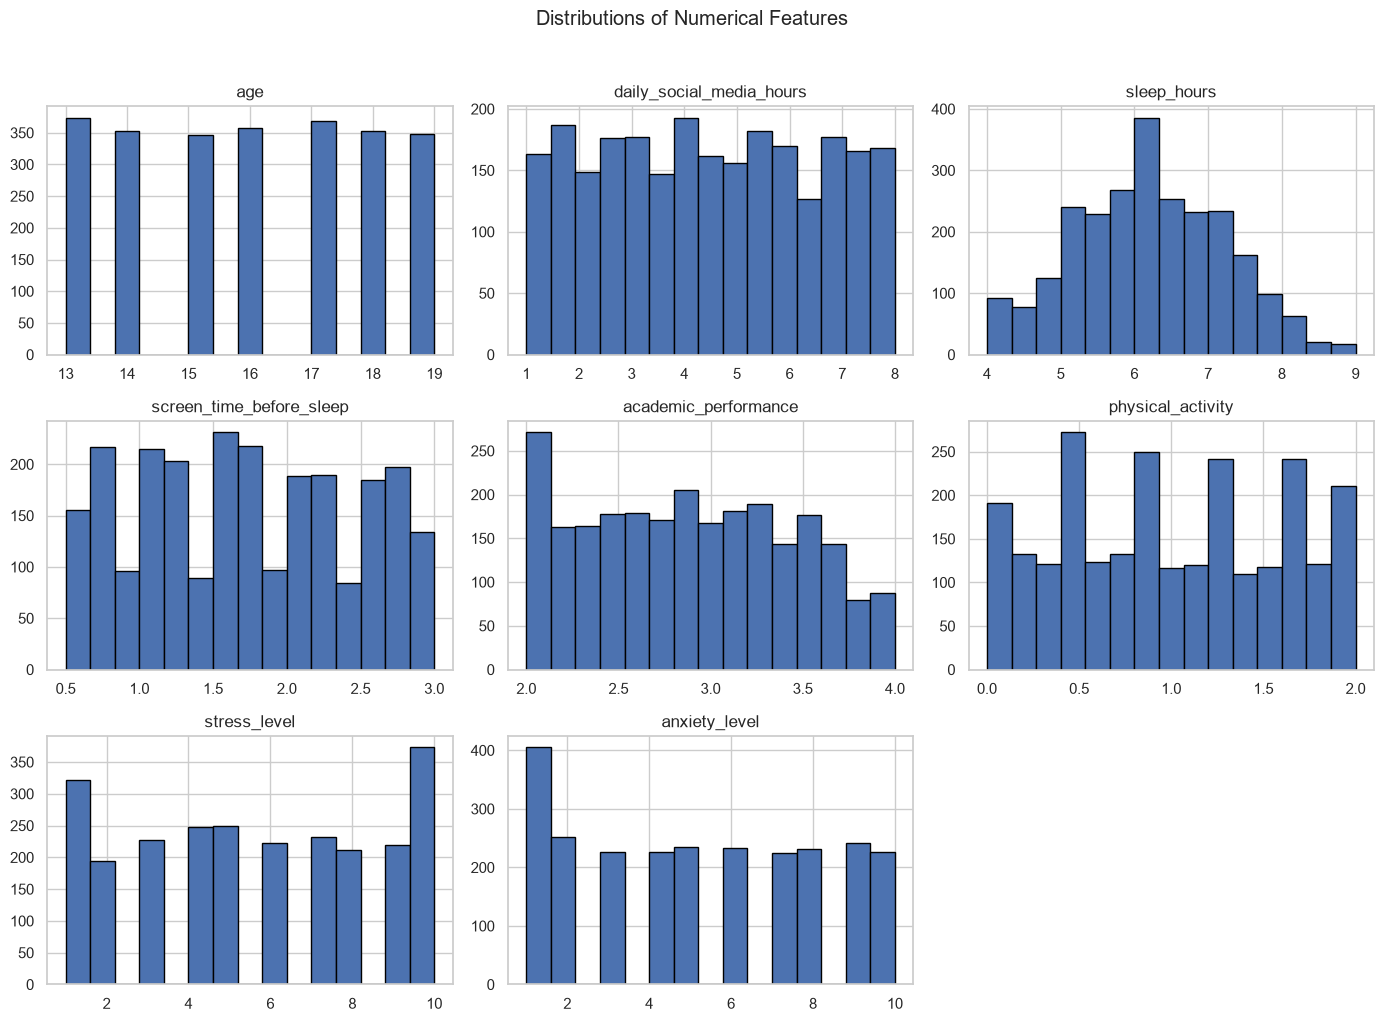

In [19]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()
display(df[numeric_columns].describe().round(2))

df[numeric_columns].hist(figsize=(14, 10), bins=15, edgecolor="black")
plt.suptitle("Distributions of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

# 5. Compare numerical features across risk groups

,daily_social_media_hours,sleep_hours,stress_level,anxiety_level,screen_time_before_sleep,academic_performance,physical_activity
depression_risk,,,,,,,
low,2.97,6.85,3.17,2.87,1.67,3.31,1.09
medium,5.42,5.78,7.16,6.65,1.73,2.62,0.94
high,6.60,5.23,9.11,8.49,1.80,2.28,0.84


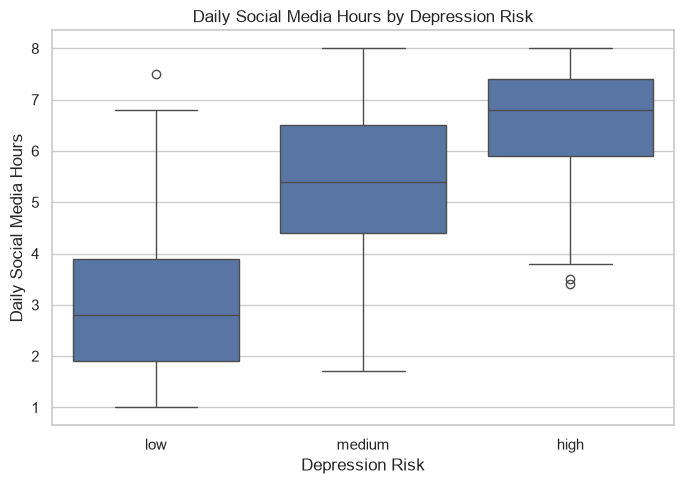

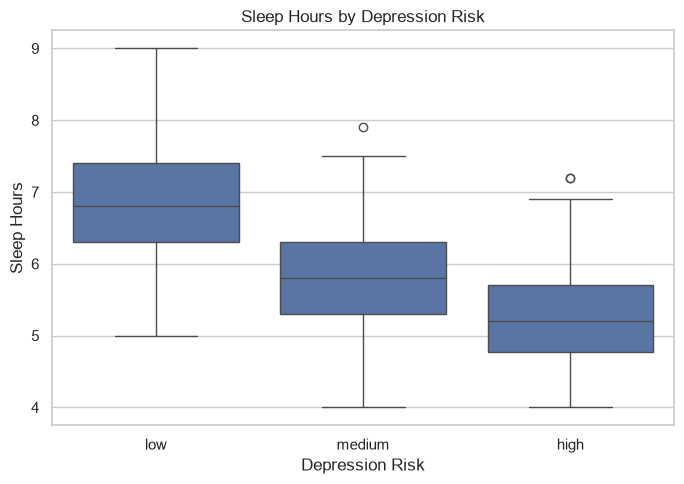

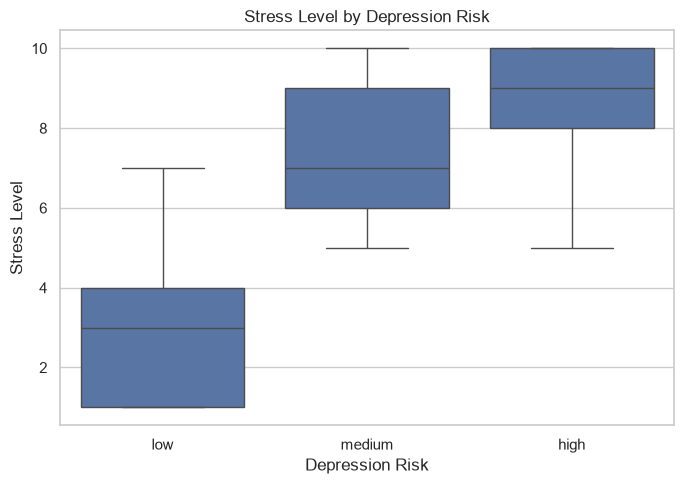

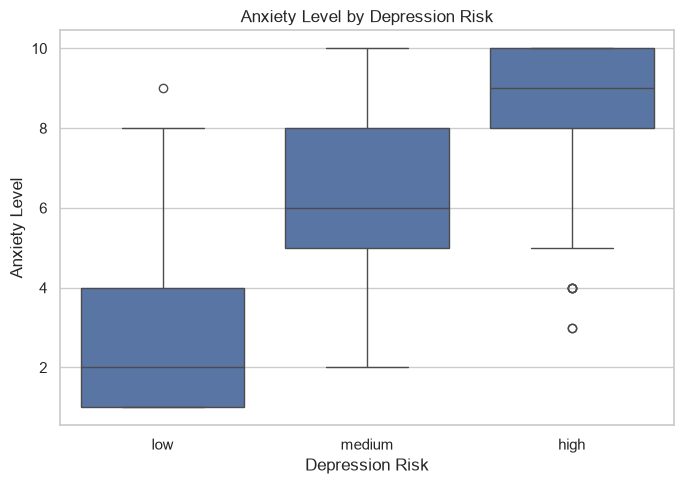

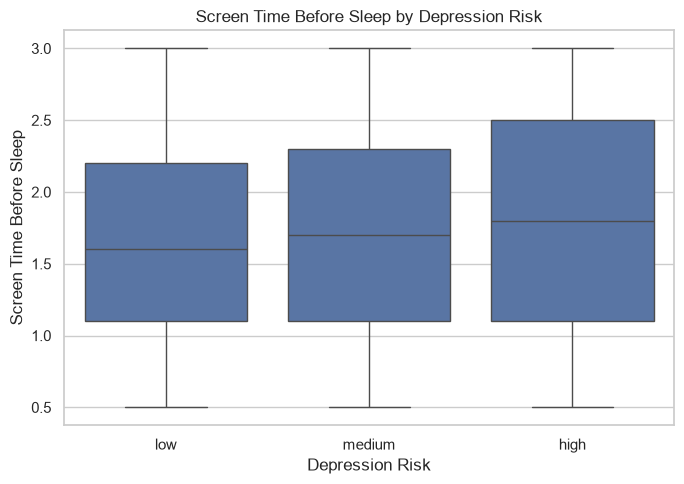

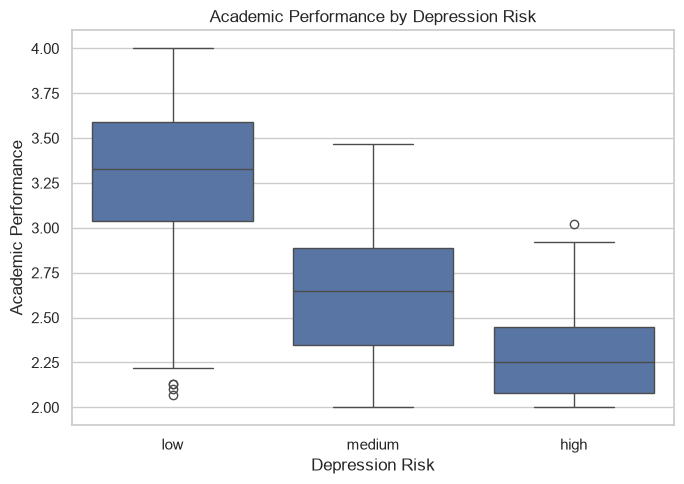

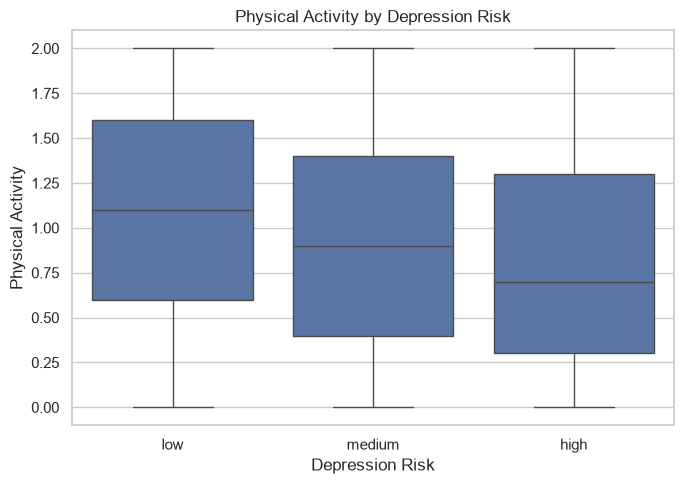

In [20]:
comparison_columns = [
    "daily_social_media_hours",
    "sleep_hours",
    "stress_level",
    "anxiety_level",
    "screen_time_before_sleep",
    "academic_performance",
    "physical_activity"
]
comparison_columns = [column for column in comparison_columns if column in df.columns]

display(
    df.groupby("depression_risk")[comparison_columns]
      .mean(numeric_only=True)
      .round(2)
      .reindex(risk_order)
)

for column in comparison_columns:
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=df, x="depression_risk", y=column, order=risk_order)
    plt.title(f"{column.replace('_', ' ').title()} by Depression Risk")
    plt.xlabel("Depression Risk")
    plt.ylabel(column.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

# 6. Categorical features and depression risk

depression_risk,high,low,medium,All
gender,,,,
female,305,620,330,1255
male,279,646,320,1245
All,584,1266,650,2500


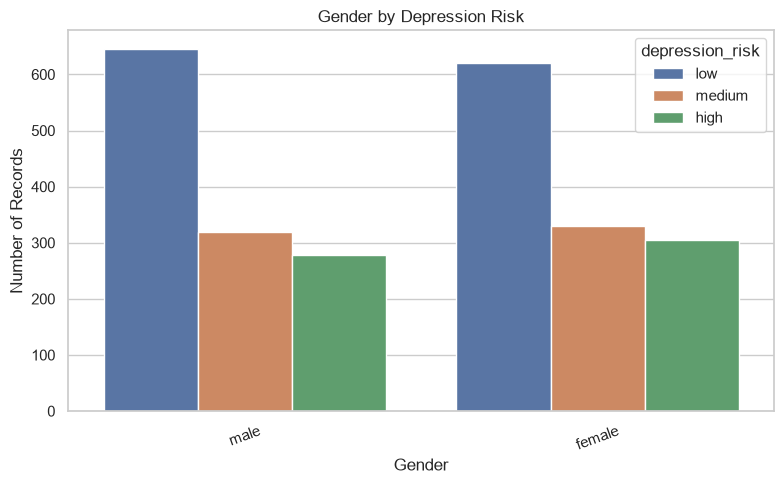

depression_risk,high,low,medium,All
platform_usage,,,,
Both,152,306,170,628
Instagram,150,318,159,627
Other,137,322,173,632
TikTok,145,320,148,613
All,584,1266,650,2500


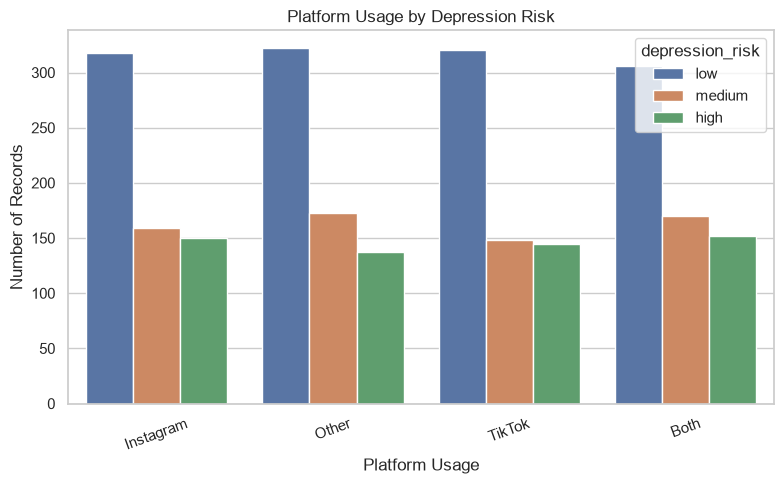

depression_risk,high,low,medium,All
social_interaction_level,,,,
high,208,415,226,849
low,186,402,222,810
medium,190,449,202,841
All,584,1266,650,2500


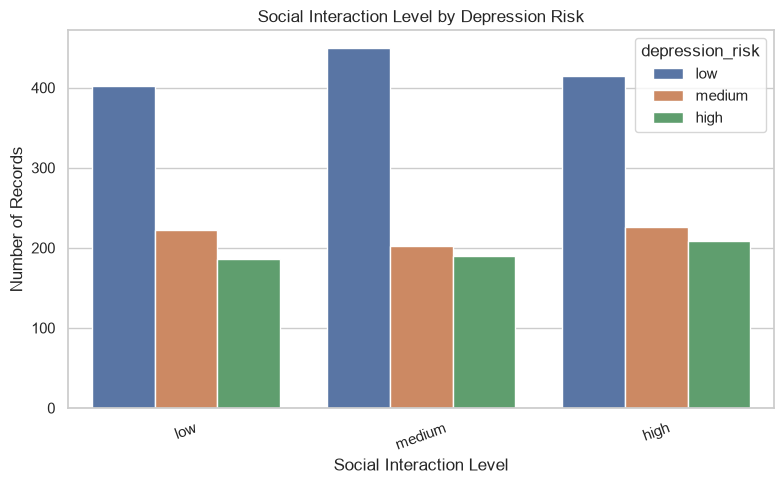

In [21]:
categorical_columns = df.select_dtypes(include="object").columns.tolist()

for column in categorical_columns:
    if column == "depression_risk":
        continue
    display(pd.crosstab(df[column], df["depression_risk"], margins=True))
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x=column, hue="depression_risk", hue_order=risk_order)
    plt.title(f"{column.replace('_', ' ').title()} by Depression Risk")
    plt.xlabel(column.replace("_", " ").title())
    plt.ylabel("Number of Records")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

## Key Findings

The dataset contains 2,500 records classified into three depression-risk categories: low, medium, and high. The low-risk group represents 50.64% of the dataset, the medium-risk group represents 26%, and the high-risk group represents 23.36%.

The analysis shows that the high-risk group has higher average daily social media usage (6.60 hours) and lower average sleep duration (5.23 hours) compared with the low-risk group, which averages 2.97 hours of daily social media usage and 6.85 hours of sleep.

Additionally, the average stress and anxiety levels are higher in the high-risk group. These patterns indicate associations between the measured lifestyle and well-being features and the dataset's depression-risk categories. They do not establish causation.



In [25]:
# Separate Features and Target

X = df.drop('depression_risk', axis=1)
y = df['depression_risk']
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

X shape: (2500, 11)
y shape: (2500,)

Target classes:
depression_risk
low       1266
medium     650
high       584
Name: count, dtype: int64


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))

X_train: (2000, 11)
X_test: (500, 11)
y_train: (2000,)
y_test: (500,)

Training distribution:
depression_risk
low       0.5065
medium    0.2600
high      0.2335
Name: proportion, dtype: float64

Testing distribution:
depression_risk
low       0.506
medium    0.260
high      0.234
Name: proportion, dtype: float64


In [29]:
categorical_columns = X_train.select_dtypes(include='object').columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(X_train[column].unique())
    print("Number of unique values:", X_train[column].nunique())


gender:
['female' 'male']
Number of unique values: 2

platform_usage:
['Both' 'Other' 'Instagram' 'TikTok']
Number of unique values: 4

social_interaction_level:
['medium' 'high' 'low']
Number of unique values: 3


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Define categorical columns
nominal_features = ['gender', 'platform_usage']
ordinal_features = ['social_interaction_level']

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('nominal', OneHotEncoder(handle_unknown='ignore'), nominal_features),

        ('ordinal', OrdinalEncoder(
            categories=[['low', 'medium', 'high']]
        ), ordinal_features)
    ],
    remainder='passthrough'
)

In [31]:
# Fit on training data and transform it
X_train_encoded = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted encoder
X_test_encoded = preprocessor.transform(X_test)

print("X_train_encoded shape:", X_train_encoded.shape)
print("X_test_encoded shape:", X_test_encoded.shape)

X_train_encoded shape: (2000, 15)
X_test_encoded shape: (500, 15)


In [34]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Select numerical columns
numerical_features = [
    'ordinal__social_interaction_level',
    'remainder__age',
    'remainder__daily_social_media_hours',
    'remainder__sleep_hours',
    'remainder__screen_time_before_sleep',
    'remainder__academic_performance',
    'remainder__physical_activity',
    'remainder__stress_level',
    'remainder__anxiety_level'
]

In [35]:
# Apply scaling to training data
X_train_scaled = X_train_encoded.copy()

X_train_scaled[:, [i for i, name in enumerate(preprocessor.get_feature_names_out())
                   if name in numerical_features]] = scaler.fit_transform(
    X_train_encoded[:, [i for i, name in enumerate(preprocessor.get_feature_names_out())
                        if name in numerical_features]]
)

# Apply the same scaling to testing data
X_test_scaled = X_test_encoded.copy()

X_test_scaled[:, [i for i, name in enumerate(preprocessor.get_feature_names_out())
                  if name in numerical_features]] = scaler.transform(
    X_test_encoded[:, [i for i, name in enumerate(preprocessor.get_feature_names_out())
                       if name in numerical_features]]
)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (2000, 15)
X_test_scaled shape: (500, 15)


# Logistic Regression.

In [36]:
from sklearn.linear_model import LogisticRegression

# Create the model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [37]:
# Make predictions on testing data
y_pred = logistic_model.predict(X_test_scaled)

# Display the first 10 predictions
print("Predictions:", y_pred[:10])

# Display the actual values
print("Actual values:", y_test.iloc[:10].values)

Predictions: ['high' 'low' 'low' 'low' 'high' 'low' 'medium' 'high' 'low' 'high']
Actual values: ['medium' 'low' 'medium' 'low' 'high' 'low' 'high' 'high' 'medium'
 'medium']


In [38]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Logistic Regression Accuracy: 0.718
Accuracy Percentage: 71.8 %


In [39]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        high       0.69      0.73      0.71       117
         low       0.86      0.87      0.86       253
      medium       0.45      0.42      0.43       130

    accuracy                           0.72       500
   macro avg       0.67      0.67      0.67       500
weighted avg       0.71      0.72      0.71       500



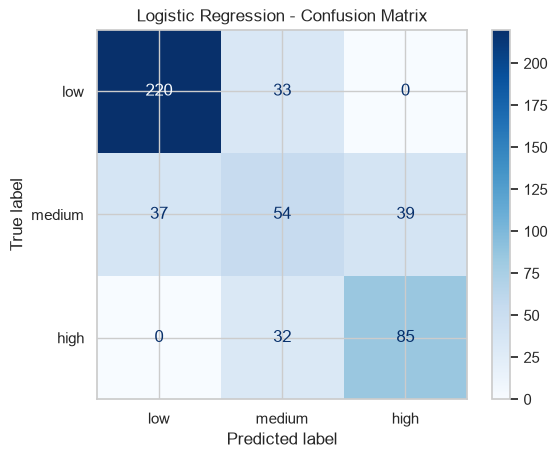

In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['low', 'medium', 'high']
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['low', 'medium', 'high']
)

display.plot(cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

# Random Forest


In [41]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train_encoded, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [42]:
# Make predictions
y_pred_rf = rf_model.predict(X_test_encoded)

# Display first 10 predictions
print("Predictions:", y_pred_rf[:10])

# Display actual values
print("Actual values:", y_test.iloc[:10].values)

Predictions: ['high' 'low' 'medium' 'low' 'high' 'low' 'medium' 'high' 'low' 'high']
Actual values: ['medium' 'low' 'medium' 'low' 'high' 'low' 'high' 'high' 'medium'
 'medium']


In [43]:
from sklearn.metrics import accuracy_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)
print("Accuracy Percentage:", accuracy_rf * 100, "%")

Random Forest Accuracy: 0.75
Accuracy Percentage: 75.0 %


In [44]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

        high       0.70      0.88      0.78       117
         low       0.92      0.81      0.86       253
      medium       0.52      0.52      0.52       130

    accuracy                           0.75       500
   macro avg       0.71      0.74      0.72       500
weighted avg       0.76      0.75      0.75       500



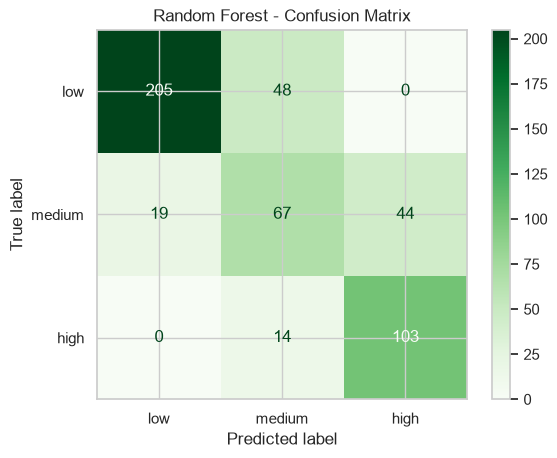

In [45]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=['low', 'medium', 'high']
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['low', 'medium', 'high']
)

display.plot(cmap='Greens')
plt.title('Random Forest - Confusion Matrix')
plt.show()

# Decision Tree Classifier.

In [47]:
from sklearn.tree import DecisionTreeClassifier

# Create the model
dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
dt_model.fit(X_train_encoded, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [48]:
# Make predictions
y_pred_dt = dt_model.predict(X_test_encoded)

# Display first 10 predictions
print("Predictions:", y_pred_dt[:10])

# Display actual values
print("Actual values:", y_test.iloc[:10].values)

Predictions: ['high' 'low' 'medium' 'low' 'high' 'low' 'medium' 'high' 'medium' 'high']
Actual values: ['medium' 'low' 'medium' 'low' 'high' 'low' 'high' 'high' 'medium'
 'medium']


In [49]:
from sklearn.metrics import accuracy_score

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt)
print("Accuracy Percentage:", accuracy_dt * 100, "%")

Decision Tree Accuracy: 0.732
Accuracy Percentage: 73.2 %


In [50]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

        high       0.69      0.74      0.71       117
         low       0.88      0.87      0.87       253
      medium       0.48      0.46      0.47       130

    accuracy                           0.73       500
   macro avg       0.68      0.69      0.69       500
weighted avg       0.73      0.73      0.73       500



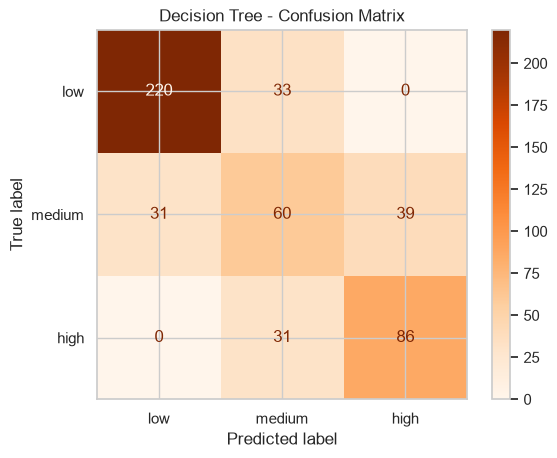

In [51]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_dt = confusion_matrix(
    y_test,
    y_pred_dt,
    labels=['low', 'medium', 'high']
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=['low', 'medium', 'high']
)

display.plot(cmap='Oranges')
plt.title('Decision Tree - Confusion Matrix')
plt.show()

# K-Nearest Neighbors (KNN)

In [100]:
from sklearn.neighbors import KNeighborsClassifier

# Create the model
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

# Train the model
knn_model.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['high','low','medium']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [101]:
# Make predictions
y_pred_knn = knn_model.predict(X_test_scaled)

# Display first 10 predictions
print("Predictions:", y_pred_knn[:10])

# Display actual values
print("Actual values:", y_test.iloc[:10].values)

Predictions: ['high' 'low' 'low' 'low' 'high' 'low' 'high' 'high' 'low' 'high']
Actual values: ['medium' 'low' 'medium' 'low' 'high' 'low' 'high' 'high' 'medium'
 'medium']


In [102]:
from sklearn.metrics import accuracy_score

accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", accuracy_knn)
print("Accuracy Percentage:", accuracy_knn * 100, "%")

KNN Accuracy: 0.704
Accuracy Percentage: 70.39999999999999 %


In [103]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

        high       0.63      0.76      0.69       117
         low       0.83      0.87      0.85       253
      medium       0.46      0.34      0.39       130

    accuracy                           0.70       500
   macro avg       0.64      0.65      0.64       500
weighted avg       0.69      0.70      0.69       500



## Machine Learning Summary

In this stage, we prepared the dataset and trained four classification models to predict `depression_risk`.

First, we divided the dataset into 80% training data and 20% testing data using stratified sampling. Then, we applied One-Hot Encoding to nominal features, Ordinal Encoding to `social_interaction_level`, and Standard Scaling to numerical features.

We trained and evaluated four models:

- Logistic Regression
- Random Forest
- Decision Tree
- K-Nearest Neighbors (KNN)

### Model Comparison

| Model | Accuracy |
|---|---:|
| Logistic Regression | 71.8% |
| Random Forest | 75.0% |
| Decision Tree | 73.2% |
| KNN | 70.4% |

### Conclusion

Random Forest achieved the highest accuracy (75%) and the best overall evaluation results so far. However, all models had difficulty predicting the Medium class.

**Next Step:** Perform Cross-Validation to check model stability before selecting the final model.

## Cross-Validation

In [104]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

In [105]:
# Define feature groups
nominal_features = ['gender', 'platform_usage']

ordinal_features = ['social_interaction_level']

numeric_features = [
    'age',
    'daily_social_media_hours',
    'sleep_hours',
    'screen_time_before_sleep',
    'academic_performance',
    'physical_activity',
    'stress_level',
    'anxiety_level'
]

# Preprocessing for models that need scaling
scaled_preprocessor = ColumnTransformer(
    transformers=[
        ('nominal', OneHotEncoder(handle_unknown='ignore'), nominal_features),
        ('ordinal', Pipeline([
            ('encoder', OrdinalEncoder(
                categories=[['low', 'medium', 'high']]
            )),
            ('scaler', StandardScaler())
        ]), ordinal_features),
        ('numeric', StandardScaler(), numeric_features)
    ]
)

# Preprocessing for tree-based models
unscaled_preprocessor = ColumnTransformer(
    transformers=[
        ('nominal', OneHotEncoder(handle_unknown='ignore'), nominal_features),
        ('ordinal', OrdinalEncoder(
            categories=[['low', 'medium', 'high']]
        ), ordinal_features),
        ('numeric', 'passthrough', numeric_features)
    ]
)

print("Preprocessing pipelines are ready!")

Preprocessing pipelines are ready!


In [106]:
# Create 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create Logistic Regression Pipeline
logistic_pipeline = Pipeline([
    ('preprocessor', scaled_preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

print("Logistic Regression pipeline is ready!")

Logistic Regression pipeline is ready!


In [107]:
# Evaluate Logistic Regression using Cross-Validation
scoring = ['accuracy', 'f1_macro', 'f1_weighted']

logistic_scores = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("Logistic Regression Cross-Validation Results:")
print("Accuracy:", logistic_scores['test_accuracy'].mean())
print("Macro F1:", logistic_scores['test_f1_macro'].mean())
print("Weighted F1:", logistic_scores['test_f1_weighted'].mean())

Logistic Regression Cross-Validation Results:
Accuracy: 0.74
Macro F1: 0.690912151478113
Weighted F1: 0.7355951735657336


In [108]:
rf_pipeline = Pipeline([
    ('preprocessor', unscaled_preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_scores = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("Random Forest Cross-Validation Results:")
print("Accuracy:", rf_scores['test_accuracy'].mean())
print("Macro F1:", rf_scores['test_f1_macro'].mean())
print("Weighted F1:", rf_scores['test_f1_weighted'].mean())

Random Forest Cross-Validation Results:
Accuracy: 0.766
Macro F1: 0.7257713358123736
Weighted F1: 0.7613548661238478


In [109]:
dt_pipeline = Pipeline([
    ('preprocessor', unscaled_preprocessor),
    ('model', DecisionTreeClassifier(random_state=42))
])

dt_scores = cross_validate(
    dt_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("Decision Tree Cross-Validation Results:")
print("Accuracy:", dt_scores['test_accuracy'].mean())
print("Macro F1:", dt_scores['test_f1_macro'].mean())
print("Weighted F1:", dt_scores['test_f1_weighted'].mean())

Decision Tree Cross-Validation Results:
Accuracy: 0.7464999999999999
Macro F1: 0.7026516585077609
Weighted F1: 0.7471057574626822


In [110]:
knn_pipeline = Pipeline([
    ('preprocessor', scaled_preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

knn_scores = cross_validate(
    knn_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("KNN Cross-Validation Results:")
print("Accuracy:", knn_scores['test_accuracy'].mean())
print("Macro F1:", knn_scores['test_f1_macro'].mean())
print("Weighted F1:", knn_scores['test_f1_weighted'].mean())

KNN Cross-Validation Results:
Accuracy: 0.7275
Macro F1: 0.6721565919082996
Weighted F1: 0.7187499027146769


## Cross-Validation Results

We applied 5-Fold Stratified Cross-Validation to evaluate the stability and performance of the four classification models using the training data.

### Model Comparison

| Model | Accuracy | Macro F1 | Weighted F1 |
|---|---:|---:|---:|
| Logistic Regression | 74.00% | 0.691 | 0.736 |
| Random Forest | 76.60% | 0.726 | 0.761 |
| Decision Tree | 74.65% | 0.703 | 0.747 |
| KNN | 72.75% | 0.672 | 0.719 |

### Conclusion

Random Forest achieved the highest scores across all three evaluation metrics, making it the strongest candidate for the final model.

KNN achieved the lowest performance, while Decision Tree and Logistic Regression showed moderate results.

The final model will be selected after reviewing its performance on the separate testing dataset.

In [111]:
# Train Random Forest on the full training set
rf_pipeline.fit(X_train, y_train)

# Predict on the unseen test set
y_pred_final = rf_pipeline.predict(X_test)

print("Final model predictions completed!")

Final model predictions completed!


In [112]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate test accuracy
final_accuracy = accuracy_score(y_test, y_pred_final)

# Display classification report
print("Final Model Accuracy:", final_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

Final Model Accuracy: 0.75

Classification Report:
              precision    recall  f1-score   support

        high       0.70      0.88      0.78       117
         low       0.92      0.81      0.86       253
      medium       0.52      0.52      0.52       130

    accuracy                           0.75       500
   macro avg       0.71      0.74      0.72       500
weighted avg       0.76      0.75      0.75       500



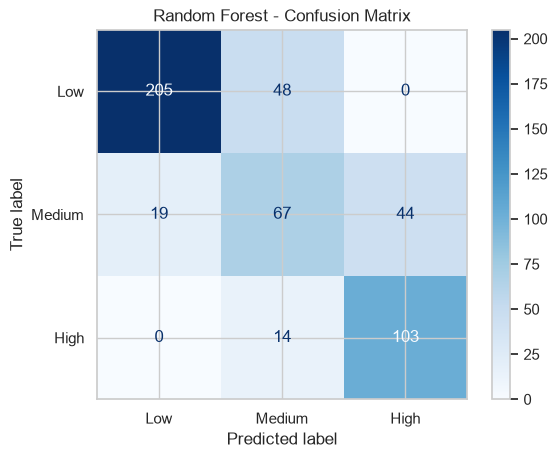

In [113]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred_final,
    labels=['low', 'medium', 'high']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot(cmap='Blues')
plt.title('Random Forest - Confusion Matrix')
plt.show()

### Confusion Matrix Analysis

The Confusion Matrix shows that the Random Forest model correctly classified 375 out of 500 test samples.

- **Low:** 205 out of 253 samples were correctly classified.
- **Medium:** 67 out of 130 samples were correctly classified.
- **High:** 103 out of 117 samples were correctly classified.

The model performed best when identifying the Low and High classes. However, it struggled to classify the Medium class, often confusing it with Low or High.

**Conclusion:** The main challenge of the Random Forest model is distinguishing between the Medium class and the other two classes.

## Feature Importance

In [114]:
import pandas as pd

# Get feature names after preprocessing
feature_names = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()

# Get feature importance values
importances = rf_pipeline.named_steps['model'].feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort features by importance
feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance_df)

                              Feature  Importance
13              numeric__stress_level    0.224791
11      numeric__academic_performance    0.167605
8   numeric__daily_social_media_hours    0.142437
14             numeric__anxiety_level    0.133401
9                numeric__sleep_hours    0.100758
12         numeric__physical_activity    0.057810
10  numeric__screen_time_before_sleep    0.056854
7                        numeric__age    0.039363
6   ordinal__social_interaction_level    0.020654
4       nominal__platform_usage_Other    0.010545
5      nominal__platform_usage_TikTok    0.010346
3   nominal__platform_usage_Instagram    0.009301
2        nominal__platform_usage_Both    0.008979
1                nominal__gender_male    0.008716
0              nominal__gender_female    0.008443


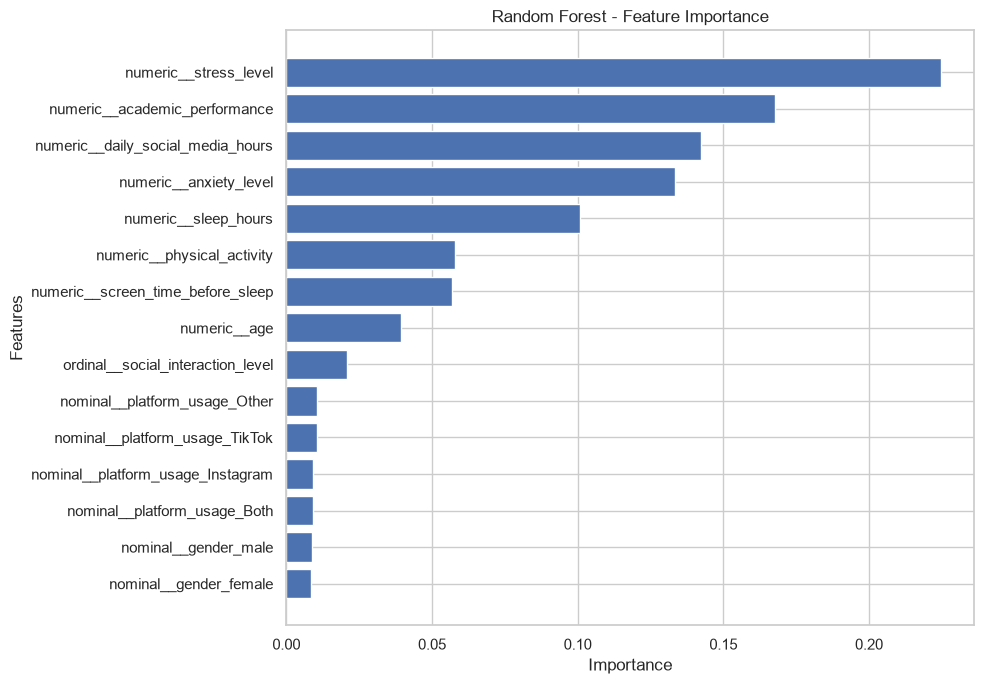

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance_df['Feature'],
    feature_importance_df['Importance']
)

plt.xlabel('Importance')
plt.ylabel('Features')
plt.title('Random Forest - Feature Importance')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Feature Importance Analysis

Feature Importance was used to identify which features contributed most to the Random Forest model's predictions.

The results showed that:

- Stress Level was the most important feature (22.48%).
- Academic Performance ranked second (16.76%).
- Daily Social Media Hours ranked third (14.24%).
- Anxiety Level and Sleep Hours also showed significant importance.
- Gender and Platform Usage had relatively low importance values.

**Conclusion:**

Stress Level, Academic Performance, Daily Social Media Hours, Anxiety Level, and Sleep Hours were the most important features used by the Random Forest model.

These results describe the model's predictive behavior and do not establish causal relationships.

In [116]:
# Create a DataFrame for actual and predicted values
error_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_final
})

# Filter incorrect predictions
errors = error_df[error_df['Actual'] != error_df['Predicted']]

print("Total incorrect predictions:", len(errors))
print("\nIncorrect Predictions:")
print(errors.head(10))

Total incorrect predictions: 125

Incorrect Predictions:
    Actual Predicted
0   medium      high
6     high    medium
8   medium       low
9   medium      high
21    high    medium
30    high    medium
31  medium       low
32     low    medium
35  medium      high
42  medium      high


In [117]:
# Count incorrect predictions by actual and predicted classes
error_analysis = errors.groupby(
    ['Actual', 'Predicted']
).size().reset_index(name='Count')

print(error_analysis)

   Actual Predicted  Count
0    high    medium     14
1     low    medium     48
2  medium      high     44
3  medium       low     19


### Error Analysis

The Random Forest model made 125 incorrect predictions out of 500 test samples.

The error analysis showed the following results:

- 48 Low samples were incorrectly classified as Medium.
- 44 Medium samples were incorrectly classified as High.
- 19 Medium samples were incorrectly classified as Low.
- 14 High samples were incorrectly classified as Medium.

**Conclusion:**

The model struggled mainly with distinguishing between the three depression risk levels, especially the Medium class. These misclassifications indicate that the model needs further improvement to achieve better classification performance.

## Model Limitations

Although the Random Forest model achieved the best overall performance, the project has some limitations:

1. **Difficulty Predicting the Medium Class:** The model struggled to distinguish between Medium and the other classes, achieving an F1-score of only 0.52 for this class.

2. **Model Performance:** The final model achieved 75% accuracy on the test dataset, which indicates that there is still room for improvement.

3. **Dataset Limitations:** The model's predictions depend on the available dataset and selected features. Therefore, the results may not represent all teenagers or different real-world situations.

4. **No Causal Relationships:** Feature Importance identifies which features contribute to the model's predictions, but it does not prove that these features cause depression.

### Possible Future Improvements

- Collect more diverse and representative data.
- Improve the prediction of the Medium class.
- Experiment with hyperparameter tuning.
- Explore additional features that may improve model performance.

## Final Conclusion

The goal of this project was to develop a Machine Learning classification model to predict teenagers' depression risk levels based on different factors, such as social media usage, sleep hours, stress level, anxiety level, and academic performance.

Four classification models were trained and evaluated: Logistic Regression, Random Forest, Decision Tree, and K-Nearest Neighbors (KNN).

After comparing their performance using Accuracy, Macro F1-score, Weighted F1-score, and 5-Fold Cross-Validation, Random Forest achieved the best overall results.

The final Random Forest model achieved **75% accuracy** on the test dataset.

Feature Importance analysis showed that Stress Level, Academic Performance, Daily Social Media Hours, Anxiety Level, and Sleep Hours were the most important features for the model's predictions.

However, the model struggled to distinguish the Medium risk class from the Low and High classes.

Overall, this project demonstrates how Machine Learning can be used to identify patterns in teenagers' mental health-related data and predict depression risk levels. The model is intended for educational and predictive purposes only and should not be used as a clinical diagnostic tool.